# Proyecto: Optimización de Rutas de Distribución usando Búsqueda Tabú
**Materia:** Métodos de Búsqueda Heurísticos para Optimización  
**Ubicación de estudio:** Culiacán, Sinaloa  

### Contexto del Problema
Una extensa cadena de restaurantes en Culiacán requiere abastecer una red de **90 sucursales** a partir de **10 Centros de Distribución (Cedis)**. Con el objetivo de reducir drásticamente los costos de combustibles y los tiempos de traslado, el problema se aborda mediante una estrategia de dos fases: **primero agrupamos las tiendas (asignando cada una a su Cedis más cercano) y después optimizamos la ruta de entrega para cada grupo de forma independiente**. Para resolver la complejidad de trazar los recorridos, se implementa el algoritmo metaheurístico de **Búsqueda de Tabú** potenciado con un operador de inversión de tramos **(2-opt)**, lo que garantiza secuencias de entrega altamente eficientes.


In [11]:
# Importación de librerías necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
import time
import folium

# Configuración de visualización para gráficas
%matplotlib inline

print("Librerías importadas correctamente.")

Librerías importadas correctamente.


## 1. Carga de Datos y Matrices
Para modelar la red logística, importamos los datos base del proyecto estrucuturados en dos matrices (evaluando las conexiones entre los 10 Cedis y las 90 sucursales):
- **Matriz de distancias:** Medidas exactas en kilómetros para dimensionar la longitud real de los recorridos.
- **Matriz de costos:** Gasto en combustible estimado en USD por cada tramo. Esta sera la variable principal (función objetivo) que nuestro algoritmo buscará minimizar.

In [12]:
# Carga de archivos Excel
archivo_distancias = 'matriz_distancias.xlsx'
archivo_costos = 'matriz_costos_combustible.xlsx'

df_dist = pd.read_excel(archivo_distancias)
df_cost = pd.read_excel(archivo_costos)

# Conversión a arreglos de numpy para acceso rápido
matriz_distancias = df_dist.values
matriz_costos = df_cost.values

print(f"Dimensiones de matriz de distancias: {matriz_distancias.shape}")
print(f"Dimensiones de matriz de costos    : {matriz_costos.shape}")

Dimensiones de matriz de distancias: (100, 100)
Dimensiones de matriz de costos    : (100, 100)


## 2. Definición del Modelo y Solución Inicial

Antes de aplicar la optimización avanzada, establecemos cómo se medirá el éxito y desde donde arrancará el algoritmo:

- **Función Objetivo:** Minimizar la suma de costos acumulados a lo largo de la ruta cerrada (salida del Cedis, visita a sucursales y regreso al Cedis).
- **Heurística Inicial:** Se utiliza el método del **Vecino más Cercano** como heurística voraz de arranque para iniciar la búsqueda en una región prometedora.

In [13]:
def calcular_costo_ruta(ruta, matriz):
    """
    Suma el costo tramo por tramo a lo largo de la ruta.
    Ruta: [Cedis, Tienda_1, Tienda_2, ..., Cedis]
    """
    costo_total = 0.0
    for i in range(len(ruta) - 1):
        origen = ruta[i]
        destino = ruta[i + 1]
        costo_total += matriz[origen][destino]
    return costo_total

def generar_ruta_vecino_cercano(cedis, lista_tiendas, matriz):
    """
    Construye una ruta inicial voraz visitando siempre el nodo disponible más cercano.
    """
    if len(lista_tiendas) == 0:
        return [cedis, cedis]
    
    ruta = [cedis]
    por_visitar = list(lista_tiendas)
    actual = cedis

    while len(por_visitar) > 0:
        menor_costo = float('inf')
        siguiente_tienda = None

        for tienda in por_visitar:
            costo = matriz[actual][tienda]
            if costo < menor_costo:
                menor_costo = costo
                siguiente_tienda = tienda

        ruta.append(siguiente_tienda)
        por_visitar.remove(siguiente_tienda)
        actual = siguiente_tienda

    # Retorno obligado al punto de partida
    ruta.append(cedis)
    return ruta

print("Funciones de evaluación e inicialización listas.")

Funciones de evaluación e inicialización listas.


## 3. Implementación del Algoritmo de Búsqueda Tabú
Estructura del algoritmo:
1. **Espacio de estados:** Vector secuencial que define el orden exacto de las paradas.
2. **Generación de vecindario:** Inversión de subsegmentos completos de la ruta (**operador 2-opt**). A diferencia de un intercambio simple, este operador es capaz de ""desenredar" cruces en la ruta, logrando descensos de costo mucho más drástico.
3. **Memoria a corto plazo (Lista Tabú):** Cola FIFO que almacena los movimientos prohibidos durante un período determinado de iteraciones (`tenure`), forzando así la exploración de nuevas rutas.
4. **Criterio de Aspiración:** Si un movimiento clasificado como tabú produce un costo estrictamente mejor que el récord histórico, se anula la restricción.

In [ ]:
def algoritmo_tabu_rutas(ruta_inicial, matriz, max_iteraciones=60, tam_tenure=5):
    """
    Ejecuta el procedimiento de Búsqueda Tabú para optimizar la ruta de distribución.
    """
    if len(ruta_inicial) <= 4:
        costo = calcular_costo_ruta(ruta_inicial, matriz)
        return ruta_inicial, costo, 0, [costo]

    ruta_actual = list(ruta_inicial)
    costo_actual = calcular_costo_ruta(ruta_actual, matriz)

    mejor_ruta = list(ruta_actual)
    mejor_costo = costo_actual

    lista_tabu = []
    historial_costos = [costo_actual]
    total_puntos = len(ruta_actual)

    for iteracion in range(1, max_iteraciones + 1):
        vecino_seleccionado = None
        costo_vecino_seleccionado = float('inf')
        movimiento_seleccionado = None

        # Exploración de vecindario mediante inversión de subsegmento (2-opt)
        for i in range(1, total_puntos - 2):
            for j in range(i + 1, total_puntos - 1):
                nueva_ruta = ruta_actual[:i] + ruta_actual[i:j+1][::-1] + ruta_actual[j+1:]
                nuevo_costo = calcular_costo_ruta(nueva_ruta, matriz)
                tienda_a = ruta_actual[i]
                tienda_b = ruta_actual[j]
                movimiento = (tienda_a, tienda_b)
                esta_en_tabu = (movimiento in lista_tabu) or ((tienda_b, tienda_a) in lista_tabu)
                criterio_aspiracion = nuevo_costo < mejor_costo

                if (not esta_en_tabu) or criterio_aspiracion:
                    if nuevo_costo < costo_vecino_seleccionado:
                        costo_vecino_seleccionado = nuevo_costo
                        vecino_seleccionado = nueva_ruta
                        movimiento_seleccionado = movimiento

        if vecino_seleccionado is None:
            break

        ruta_actual = vecino_seleccionado
        costo_actual = costo_vecino_seleccionado

        if costo_actual < mejor_costo:
            mejor_costo = costo_actual
            mejor_ruta = list(ruta_actual)

        lista_tabu.append(movimiento_seleccionado)
        if len(lista_tabu) > tam_tenure:
            lista_tabu.pop(0)

        historial_costos.append(costo_actual)

    return mejor_ruta, mejor_costo, iteracion, historial_costos    
print("Algoritmo Tabú implementado correctamente.")     

Algoritmo Tabú implementado correctamente.


## 4. Ejecución del Experimento y Comparación de Métricas
En esta sección escalamos la optimización a toda la infraestructura logística de Culiacán, ejecutando el plan en dos fases consecutivas:

1. **Fase de Agrupación (Clustering):** Evaluamos la matriz de distancias para asignar automaticamente cada una de las 90 sucursales (nodos 10 al 99) a su Centro de Distribución más cercano (nodos 0 al 9).
2. **Fase de Ruteo (Routig):** Iteramos sobre los 10 Cedis. Para cada conjunto de tiendas, generamos una ruta inicial mediante el Vecino Más Cercano y la sometemos a la optmización profunda de la Búsqueda Tabú.

Al finalizar, se consolida un balance global para comparar el costo, la distancia y el tiempo de conducción de la solución inicial frente a la red optimizada.

In [ ]:
print("\n" + "="*70)
print("ASIGNACIÓN DE SUCURSALES AL CENTRO DE DISTRIBUCIÓN MÁS CERCANO")
print("="*70)

velocidad_promedio_kmh = 40.0
max_iteraciones_tabu = 60

#Asignar cada tienda (10 a 99) a su Cedis más cercano (0 a 9)
tienda_a_cedis = {}
for tienda in range(10, 100):
    closest_cedis = min(range(10), key=lambda c: matriz_distancias[c, tienda])
    tienda_a_cedis[tienda] = closest_cedis

#Optimizar ruta independiente para cada Cedis
resultados_por_cedis = []
rutas_optimas_completas = {}

historial_costo_global = [0.0] * (max_iteraciones_tabu + 1)

for c in range(10):
    tiendas_asignadas = [t for t, assigned in tienda_a_cedis.items() if assigned == c]

    # Ruta inicial Voraz
    r_ini = generar_ruta_vecino_cercano(c, tiendas_asignadas, matriz_costos)
    c_ini = calcular_costo_ruta(r_ini, matriz_costos)
    d_ini = calcular_costo_ruta(r_ini, matriz_distancias)

    # Optimización Tabú
    r_opt, c_opt, iters, hist = algoritmo_tabu_rutas(r_ini, matriz_costos, max_iteraciones=60, tam_tenure=5)
    d_opt = calcular_costo_ruta(r_opt, matriz_distancias)

    rutas_optimas_completas[f"Cedis {c+1}"] = r_opt

    # Actualizar el historial de costos global
    while len(hist) < (max_iteraciones_tabu + 1):
        hist.append(hist[-1])

    #Suma de iteracion por iteracion
    for i in range(max_iteraciones_tabu + 1):
        historial_costo_global[i] += hist[i]    

    # Calculo de tiempo
    tiempo_ini_hrs = d_ini / velocidad_promedio_kmh
    tiempo_opt_hrs = d_opt / velocidad_promedio_kmh
    ahorro_tiempo_hrs = tiempo_ini_hrs - tiempo_opt_hrs

    ahorro = ((c_ini - c_opt) / c_ini) * 100 if c_ini > 0 else 0.0

    resultados_por_cedis.append({
        'Centro de Distribución': f'Cedis {c+1} (Nodo {c})',
        'Tiendas': len(tiendas_asignadas),
        'Costo Inicial ($)': round(c_ini, 2),
        'Costo Tabú ($)': round(c_opt, 2),
        'Dist. Inicial (km)': round(d_ini, 2),
        'Dist. Tabú (km)': round(d_opt, 2),
        'Tiempo Inicial (hrs)': round(tiempo_ini_hrs, 2),
        'Tiempo Tabú (hrs)': round(tiempo_opt_hrs, 2),
        'Ahorro Tiempo (hrs)': round(ahorro_tiempo_hrs,2),
        'Ahorro (%)': round(ahorro, 2)
    })

df_reporte = pd.DataFrame(resultados_por_cedis)

# Totales globales de toda la cadena de restaurantes
total_costo_ini = df_reporte['Costo Inicial ($)'].sum()
total_costo_tabu = df_reporte['Costo Tabú ($)'].sum()
total_dist_ini = df_reporte['Dist. Inicial (km)'].sum()
total_dist_tabu = df_reporte['Dist. Tabú (km)'].sum()
total_tiempo_ini = df_reporte['Tiempo Inicial (hrs)'].sum()
total_tiempo_tabu = df_reporte['Tiempo Tabú (hrs)'].sum()
ahorro_tiempo =total_tiempo_ini - total_tiempo_tabu
ahorro_global = ((total_costo_ini - total_costo_tabu) / total_costo_ini) * 100

print(df_reporte.to_string(index=False))

print("="*70)
print(f"BALANCE GLOBAL DE TODA LA RED EN CULIACÁN (10 CEDIS / 90 TIENDAS)")
print(f"- Costo Inicial Red (Voraz)  : ${total_costo_ini:.2f} USD")
print(f"- Costo Final Red (Tabú 2-opt): ${total_costo_tabu:.2f} USD")
print(f"- Distancia Total Inicial     : {total_dist_ini:.2f} km")
print(f"- Distancia Total Optimizada  : {total_dist_tabu:.2f} km")
print(f"- Tiempo Total Inicial        : {total_tiempo_ini:.2f} hrs")
print(f"- Tiempo Total Optimizado     : {total_tiempo_tabu:.2f} hrs")
print(f"- AHORRO GLOBAL DE TIEMPO     : {ahorro_tiempo:.2f} hrs por vuelta")
print(f"- AHORRO GLOBAL OBTENIDO      : {ahorro_global:.2f} %")
print("="*70)


ASIGNACIÓN DE SUCURSALES AL CENTRO DE DISTRIBUCIÓN MÁS CERCANO
Centro de Distribución  Tiendas  Costo Inicial ($)  Costo Tabú ($)  Dist. Inicial (km)  Dist. Tabú (km)  Tiempo Inicial (hrs)  Tiempo Tabú (hrs)  Ahorro Tiempo (hrs)  Ahorro (%)
      Cedis 1 (Nodo 0)        5               2.06            2.03               13.70            13.56                  0.34               0.34                 0.00        1.03
      Cedis 2 (Nodo 1)        6               2.74            2.45               18.27            16.31                  0.46               0.41                 0.05       10.75
      Cedis 3 (Nodo 2)        4               2.17            1.82               14.48            12.15                  0.36               0.30                 0.06       16.11
      Cedis 4 (Nodo 3)       21               5.70            5.01               38.01            33.41                  0.95               0.84                 0.11       12.10
      Cedis 5 (Nodo 4)       11               

## 5. Análisis Visual de Resultados (Comparativo y Convergencia)

Para evaluar el impacto real de la optmización en la red logística, generamos dos representaciones gráficas clave:

1. **Comparativa por Centro de Distribución:** Un gráfico de barras que contrasta el costo de la solución inicial (Voraz) frente al resultado final (Tabú) para cada uno de los 10 Cedis, evidenciando visualmente el margen de ahorro obtenido por zona.
2. **Evolución del Costo Global:** Un gráfico trazado a lo largo de las iteraciones que permite analizar el comportamiento dinámico del algoritmo. Aquí se observa cómo la Búsqueda Tabú explora el espacio de soluciones, acepta movimientos estratégicos para escapar de mínimos locales y finalmente se estabiliza en el costo óptimo de la red.

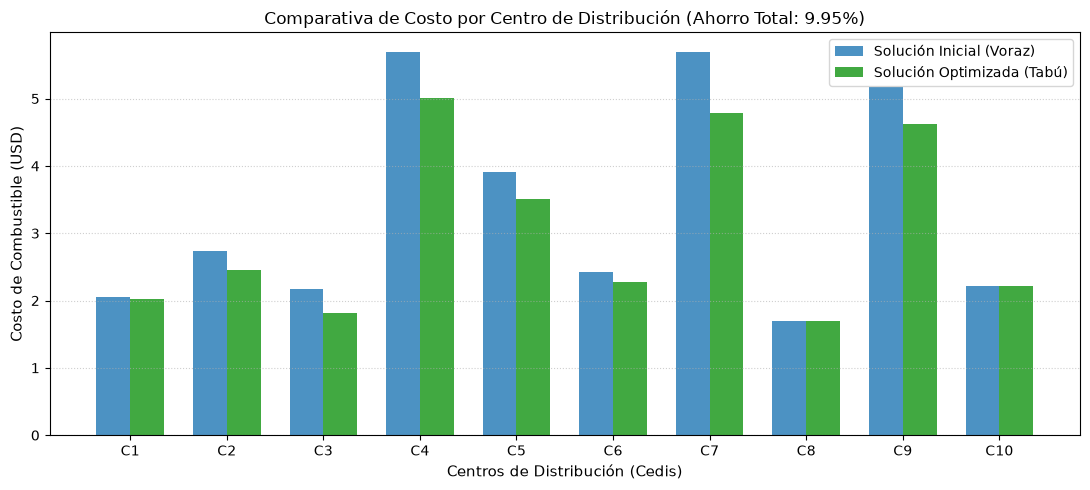

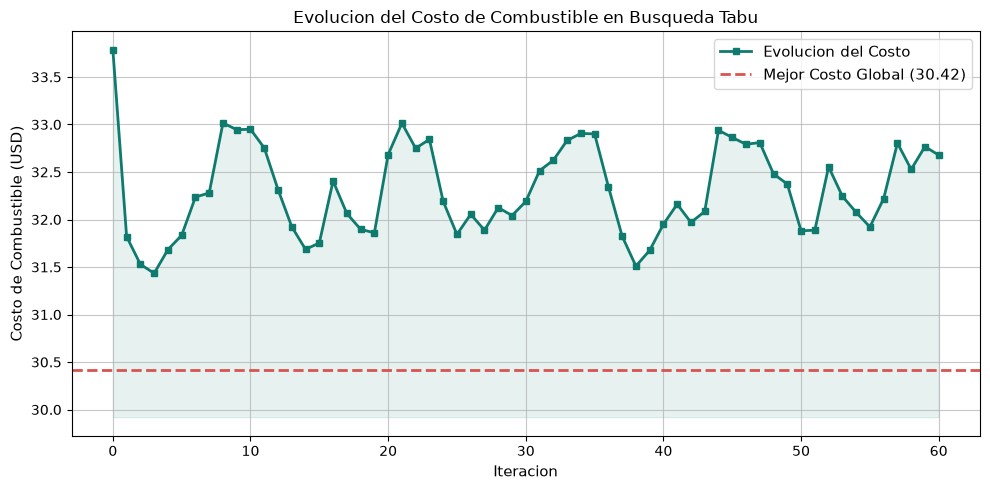

In [16]:
centros_etiquetas = [f"C{i+1}" for i in range(10)]
costos_antes = df_reporte['Costo Inicial ($)'].values
costos_despues = df_reporte['Costo Tabú ($)'].values

x = np.arange(len(centros_etiquetas))
ancho = 0.35

plt.figure(figsize=(11, 5))
plt.bar(x - ancho/2, costos_antes, ancho, label='Solución Inicial (Voraz)', color='#1f77b4', alpha=0.8)
plt.bar(x + ancho/2, costos_despues, ancho, label='Solución Optimizada (Tabú)', color='#2ca02c', alpha=0.9)

plt.xlabel('Centros de Distribución (Cedis)', fontsize=11)
plt.ylabel('Costo de Combustible (USD)', fontsize=11)
plt.title(f'Comparativa de Costo por Centro de Distribución (Ahorro Total: {ahorro_global:.2f}%)', fontsize=12)
plt.xticks(x, centros_etiquetas)
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig('comparativa_red_completa.png', dpi=300)
plt.show()

plt.figure(figsize=(10,5))

plt.fill_between(range(len(historial_costo_global)), historial_costo_global, total_costo_tabu - 0.5, color='#0f7b6e', alpha=0.1)
plt.plot(historial_costo_global, marker='s', markersize=5, linestyle='-', color='#0f7b6e', linewidth=2, label= 'Evolucion del Costo')
plt.axhline(y=total_costo_tabu, color='#d9534f', linestyle='--', linewidth=2, label=f'Mejor Costo Global ({total_costo_tabu:.2f})')

plt.title('Evolucion del Costo de Combustible en Busqueda Tabu', fontsize=12)
plt.xlabel('Iteracion',fontsize=11)
plt.ylabel('Costo de Combustible (USD)', fontsize=11)
plt.grid(True, linestyle='-', alpha=0.7)
plt.legend(fontsize=11)
plt.tight_layout()
plt.savefig('evolucion_costo_tabu.png', dpi=300)
plt.show()

## 6. Mapeo Geoespacial de Rutas Óptimas

Para traducir los resultados matemáticos en una herramienta logística procesable, proyectamos la solución final sobre un mapa interactivo de Culiacán utilizando la librería **Folium**.

En esta visualización:
* **Centros de Distribución (Cedis):** Se identifican con marcadores rojos en forma de casa.
* **Sucursales:** Se representan con puntos del mismo color que su ruta asignada.
* **Recorridos:** Las líneas trazadas muestran la secuencia de visita exacta dictada por el algoritmo. Cada uno de los 10 Cedis tiene un color distinto para evitar confusiones visuales.
* **Exploración:** El mapa incluye un panel de control de capas que permite ocultar o mostrar rutas individuales para realizar un análisis detallado por sector logístico.

In [17]:
print("\nGenerando mapa geoespacial de rutas optimas")

df_coordenada_tienda = pd.read_excel('datos_distribucion_tiendas.xlsx')
coordenadas_nodos = df_coordenada_tienda[['Latitud_WGS84', 'Longitud_WGS84']].values

#Calcular el centro del mapa
latitud_central = df_coordenada_tienda['Latitud_WGS84'].mean()
longitud_central = df_coordenada_tienda['Longitud_WGS84'].mean()

#Inicializar el mapa centrado en Culiacán
mapa_rutas = folium.Map(location=[latitud_central, 
                                  longitud_central], 
                                  zoom_start=10, 
                                  tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}',
                                  attr='Esri')

#Colores distintos para cada Cedis
colores_rutas = ['#d6194b', '#3cb44b', '#ffe119', '#4363d8', '#f58231',
                 '#911eb4', '#46f0f0', '#f032e6', '#bcf60c', '#fabebe']

contador_color = 0

#iteracion sobre cada Cedis y sus rutas optimas
for nombre_cedis in rutas_optimas_completas:
    secuencia_ruta = rutas_optimas_completas[nombre_cedis]
    color_actual = colores_rutas[contador_color]

    capa_cedis = folium.FeatureGroup(name=f"Ruta {nombre_cedis}", show=False)

# Agregar marcador para el Cedis
    puntos_ruta = []
    for nodo in secuencia_ruta:
        latitud = coordenadas_nodos[nodo][0]
        longitud = coordenadas_nodos[nodo][1]
        puntos_ruta.append((latitud, longitud))

#Dibujar la linea de la ruta en el mapa
    folium.PolyLine(locations=puntos_ruta, 
                    color=color_actual, 
                    weight=4, 
                    opacity=0.8, 
                    tooltip=f"Ruta Optimizada: {nombre_cedis}").add_to(capa_cedis)

# Agregar marcadores para cada nodo en la ruta
    posicion_lista = 0
    for nodo in secuencia_ruta:
        lati = puntos_ruta[posicion_lista][0]
        long = puntos_ruta[posicion_lista][1]

        if nodo < 10:
            folium.Marker(location=[lati, long], 
                          popup=f"<b>{nombre_cedis}</b>", 
                          icon=folium.Icon(color='red', icon='home')).add_to(mapa_rutas)
        else:
            folium.CircleMarker(location= [lati, long], 
                                radius=4, 
                                color=color_actual, 
                                fill=True, 
                                fillColor=color_actual, 
                                fillOpacity=0.9, 
                                popup=f"Sucursal {nodo}").add_to(capa_cedis)
        posicion_lista += 1
    contador_color += 1
    capa_cedis.add_to(mapa_rutas)

#Activar control de capas para mostrar/ocultar rutas por Cedis
folium.LayerControl(collapsed=False).add_to(mapa_rutas)
mapa_rutas.save('mapa_rutas_optimas.html')

mapa_rutas  


Generando mapa geoespacial de rutas optimas
